# Specification Quality and Follow-up Code PR Activity

This notebook tests whether the quality of eligible specifications is associated with subsequent merged code-related pull request activity.

**Analysis windows:** 30 days (primary) and 90 days (robustness analysis). Both windows require complete observation through the confirmed data collection cutoff of **July 14, 2026**. This is to give all observations in each analysis a fair opportunity to gather follow-up activity.

**Outcome definition:** the number of later merged, code-changing PRs in the collected PR data that touch at least one code file changed by the spec's initial implementation PR. This is follow-up code activity, not necessarily bug fixes. Furthermore, the PR collection is spec-associated, so it may not represent all repository activity.

_Run cells from top to bottom. Data files are expected in `data/`._

## 1. Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import statsmodels.formula.api as smf

spec_files = pd.read_parquet("data/spec_files.parquet")
features = pd.read_parquet("data/spec_content_features.parquet")
pull_requests = pd.read_parquet("data/pull_requests.parquet")
pr_files = pd.read_parquet("data/pr_files.parquet")

print(f"{len(spec_files):,} spec files across {spec_files['repo_name'].nunique():,} repositories")
print(f"{len(pull_requests):,} PR records; {len(pr_files):,} PR-file records")

28,583 spec files across 415 repositories
5,335 PR records; 288,267 PR-file records


## 2. Filter eligible specifications

Keep English specs with at least 100 words, 10 lines, and 2 headings; remove detected placeholders; require at least two of the eight substantive features. These rules define the eligible population for the analysis.

In [2]:
QUALITY_FEATURES = [
    "has_requirements", "has_acceptance_criteria", "has_user_scenarios",
    "has_success_criteria", "has_purpose", "has_overview",
    "has_edge_cases", "has_dependencies"
]

english = features.loc[features["lang"].eq("en")].copy()
usable = english.loc[
    (english["n_words"] >= 100)
    & (english["n_lines"] >= 10)
    & (english["n_headings"] >= 2)
    & (english["has_lorem"].fillna(0).eq(0))
    & (english["has_unfilled_placeholder"].fillna(0).eq(0))
].copy()

usable["n_substantive_features"] = usable[QUALITY_FEATURES].fillna(0).sum(axis=1)
eligible = usable.loc[usable["n_substantive_features"] >= 2].copy()

filter_counts = pd.Series({
    "All feature records": len(features),
    "English": len(english),
    "Content and placeholder criteria": len(usable),
    "Eligible (2+ substantive features)": len(eligible)
})
display(filter_counts.to_frame("n"))
display(english[["n_words", "n_lines", "n_headings"]].describe(percentiles=[.05,.25,.5,.75,.95]))

,n
All feature records,28583
English,27936
Content and placeholder criteria,24240
Eligible (2+ substantive features),6336


,n_words,n_lines,n_headings
count,27936.000000,27936.00000,27936.000000
mean,736.771084,90.04700,14.491982
std,1132.285330,130.31456,15.723593
min,7.000000,2.00000,0.000000
5%,91.000000,13.00000,3.000000
25%,224.000000,30.00000,6.000000
50%,423.000000,56.00000,11.000000
75%,839.000000,107.00000,18.000000
95%,2353.000000,262.00000,36.000000
max,45425.000000,6610.00000,945.000000


## 3. Identify initial implementation PRs and follow-up activity

An initial implementation is the earliest merged PR in the collected data that modifies an eligible spec and code. Follow-up PRs must be merged later, change code, and touch at least one code path modified by that initial PR. PR identifiers are matched using tool, repository, and PR number.

In [3]:
PR_KEY = ["tool", "repo_name", "pr_number"]

# Attach repository, path, and tool metadata to eligible specs.
spec_meta = eligible[["file_url_sha16"]].merge(
    spec_files[["file_url_sha16", "repo_name", "file_path", "spec_tool"]]
      .drop_duplicates("file_url_sha16"),
    on="file_url_sha16", how="left", validate="one_to_one"
).rename(columns={"spec_tool": "tool"})
spec_meta = spec_meta.dropna(subset=["tool", "repo_name", "file_path"])

# Find merged PRs that changed both an eligible spec and code.
pr_meta = pull_requests[PR_KEY + ["merged_at", "is_merged", "touches_code"]].drop_duplicates(PR_KEY)
spec_changes = pr_files.loc[pr_files["is_spec"].eq(1)].merge(
    spec_meta, on=["tool", "repo_name", "file_path"], how="inner"
).merge(pr_meta, on=PR_KEY, how="inner")

initial_candidates = spec_changes.loc[
    spec_changes["is_merged"].eq(1) & spec_changes["touches_code"].eq(1)
].copy()
initial_candidates["merged_at"] = pd.to_datetime(initial_candidates["merged_at"], utc=True, errors="coerce")
initial_candidates = initial_candidates.dropna(subset=["merged_at"]).sort_values("merged_at")
initial_prs = initial_candidates.drop_duplicates("file_url_sha16")[["file_url_sha16"] + PR_KEY + ["merged_at"]].rename(
    columns={"pr_number": "initial_pr", "merged_at": "initial_date"}
)
print(f"Eligible specs: {len(eligible):,}")
print(f"Specs with identified initial implementation: {len(initial_prs):,}")

# Collect code paths changed in each initial implementation.
initial_code = pr_files.loc[pr_files["is_code"].eq(1)].merge(
    initial_prs, left_on=PR_KEY, right_on=["tool", "repo_name", "initial_pr"], how="inner"
)
initial_paths = initial_code.groupby("file_url_sha16")["file_path"].agg(set).to_dict()
initial_code_file_count = initial_code.groupby("file_url_sha16")["file_path"].nunique()

# Collect code paths for later merged code-changing PRs in the available PR dataset.
later_meta = pull_requests.loc[
    pull_requests["is_merged"].eq(1) & pull_requests["touches_code"].eq(1), PR_KEY + ["merged_at"]
].copy()
later_meta["merged_at"] = pd.to_datetime(later_meta["merged_at"], utc=True, errors="coerce")
later_meta = later_meta.dropna(subset=["merged_at"])
later_code = pr_files.loc[pr_files["is_code"].eq(1)].merge(later_meta, on=PR_KEY, how="inner")
later_prs = later_code.groupby(PR_KEY + ["merged_at"])["file_path"].agg(set).reset_index(name="code_paths")
later_by_repo = {key: grp.sort_values("merged_at") for key, grp in later_prs.groupby(["tool", "repo_name"])}

Eligible specs: 6,336
Specs with identified initial implementation: 3,729


## 4. Count follow-up PRs in each window

Counts are cumulative: a PR within 30 days is also within 90 days. Specs with no identified initial implementation, or no initial code paths to compare, remain missing (not zero). A zero means the initial code paths had no matching follow-up PR in that window.

In [10]:
FOLLOWUP_WINDOWS = [30, 90]
followup_rows = []

for spec in initial_prs.itertuples(index=False):
    spec_id, tool, repo, initial_pr, initial_date = (
        spec.file_url_sha16, spec.tool, spec.repo_name, spec.initial_pr, spec.initial_date
    )
    paths = initial_paths.get(spec_id, set())
    row = {
        "file_url_sha16": spec_id,
        "initial_pr": initial_pr,
        "initial_date": initial_date,
        "initial_code_file_count": len(paths),
    }
    if not paths:
        row.update({f"followup_code_prs_{d}d": pd.NA for d in FOLLOWUP_WINDOWS})
        followup_rows.append(row)
        continue

    counts = {d: 0 for d in FOLLOWUP_WINDOWS}
    repo_prs = later_by_repo.get((tool, repo))
    if repo_prs is not None:
        for pr in repo_prs.itertuples(index=False):
            if pr.pr_number == initial_pr:
                continue
            days = (pr.merged_at - initial_date).total_seconds() / 86400
            if days <= 0 or not paths.intersection(pr.code_paths):
                continue
            for d in FOLLOWUP_WINDOWS:
                if days <= d:
                    counts[d] += 1
    row.update({f"followup_code_prs_{d}d": counts[d] for d in FOLLOWUP_WINDOWS})
    followup_rows.append(row)

followups = pd.DataFrame(followup_rows)
spec_results = eligible.merge(followups, on="file_url_sha16", how="left")

# Keep metadata needed later for sample definition and regressions.
metadata = spec_files[["file_url_sha16", "spec_tool", "repo_name"]].drop_duplicates("file_url_sha16")
spec_results = spec_results.merge(metadata, on="file_url_sha16", how="left", validate="one_to_one")
spec_results = spec_results.rename(columns={"spec_tool": "tool"})

print("Eligible specifications:", f"{len(spec_results):,}")
print("Initial implementations identified:", f"{spec_results['initial_pr'].notna().sum():,}")
print("Specs with measurable follow-up:", f"{spec_results['followup_code_prs_90d'].notna().sum():,}")
display(spec_results[["followup_code_prs_30d", "followup_code_prs_90d"]].describe())
# Save this intermediate dataset if desired.
spec_results.to_parquet("eligible_spec_followups.parquet", index=False)

Eligible specifications: 6,336
Initial implementations identified: 3,729
Specs with measurable follow-up: 3,729


,followup_code_prs_30d,followup_code_prs_90d
count,3729.000000,3729.000000
mean,8.547064,13.406811
std,11.383460,18.607188
min,0.000000,0.000000
25%,1.000000,2.000000
50%,4.000000,5.000000
75%,10.000000,16.000000
max,57.000000,101.000000


## 5. Construct specification quality score

The score is the sum of the eight binary substantive features (range 0–8). Eligibility requires at least two features, so scores below 2 are absent from this analysis.

In [12]:
spec_results["quality_score"] = spec_results[QUALITY_FEATURES].fillna(0).sum(axis=1)
display(spec_results["quality_score"].value_counts().sort_index().to_frame("specs"))

,specs
quality_score,
2,3762
3,746
4,1134
5,633
6,58
7,3


## 6. Descriptive associations

For each follow-up window, show counts, mean and median follow-up activity by quality score, Spearman rank correlation, and the outcome distribution. Descriptive statistics use specs with an identified initial implementation and measurable follow-up for that window, before complete-window restriction.


--- 30-day window: N=3,729 ---


,n,mean,median
quality_score,,,
2,2458,10.423922,5.0
3,405,7.103704,4.0
4,628,4.264331,2.0
5,215,2.827907,2.0
6,21,4.000000,1.0
7,2,1.500000,1.5


Spearman rho=-0.270; p=2.603e-63


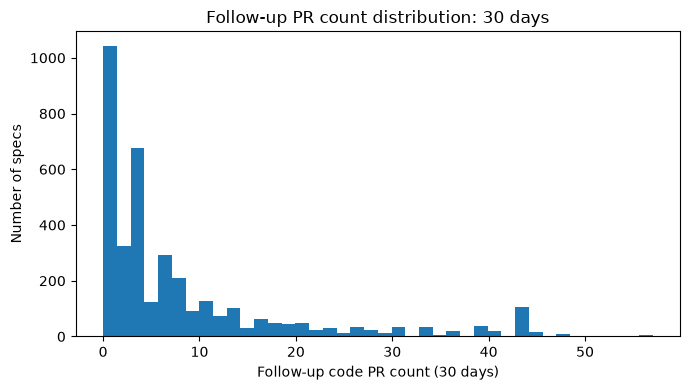


--- 90-day window: N=3,729 ---


,n,mean,median
quality_score,,,
2,2458,16.385679,7.0
3,405,10.822222,5.0
4,628,6.764331,3.0
5,215,4.516279,3.0
6,21,5.333333,3.0
7,2,2.000000,2.0


Spearman rho=-0.242; p=1.051e-50


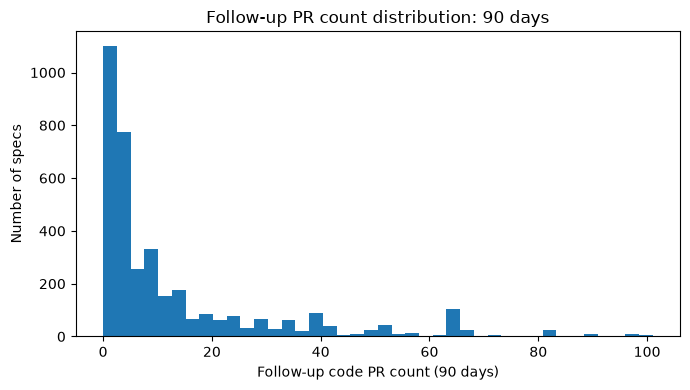

In [13]:
for window in FOLLOWUP_WINDOWS:
    outcome = f"followup_code_prs_{window}d"
    data = spec_results.dropna(subset=["quality_score", outcome]).copy()
    print(f"\n--- {window}-day window: N={len(data):,} ---")
    display(data.groupby("quality_score")[outcome].agg(n="count", mean="mean", median="median"))
    rho, p = spearmanr(data["quality_score"], data[outcome])
    print(f"Spearman rho={rho:.3f}; p={p:.4g}")
    plt.figure(figsize=(7, 4))
    plt.hist(data[outcome], bins=40)
    plt.xlabel(f"Follow-up code PR count ({window} days)")
    plt.ylabel("Number of specs")
    plt.title(f"Follow-up PR count distribution: {window} days")
    plt.tight_layout()
    plt.show()

## 7. Complete follow-up window and attrition analysis

The data collection cutoff is July 14, 2026. A spec is eligible for a window if its initial implementation date is at least that many days before the cutoff. The comparisons below describe retained versus excluded implementations for each horizon. This restriction is necessary so each observation has the same opportunity to accumulate follow-up activity within its chosen window.

In [14]:
DATA_CUTOFF = pd.Timestamp("2026-07-14", tz="UTC")
attrition = spec_results.loc[spec_results["initial_date"].notna()].copy()
attrition["initial_date"] = pd.to_datetime(attrition["initial_date"], utc=True, errors="coerce")

for window in FOLLOWUP_WINDOWS:
    cutoff_date = DATA_CUTOFF - pd.Timedelta(days=window)
    flag = f"complete_{window}d"
    attrition[flag] = attrition["initial_date"] <= cutoff_date
    print(f"\n--- {window}-day follow-up ---")
    print(f"Date cutoff for initial PR: {cutoff_date}")
    print("Retained:", int(attrition[flag].sum()))
    print("Excluded:", int((~attrition[flag]).sum()))
    display(attrition.groupby(flag).agg(
        n=("file_url_sha16", "count"),
        mean_quality=("quality_score", "mean"),
        median_quality=("quality_score", "median"),
        mean_words=("n_words", "mean"),
        median_words=("n_words", "median"),
        mean_initial_date=("initial_date", "mean")
    ))
    print("Tools among retained:")
    display(attrition.loc[attrition[flag], "tool"].value_counts())
    print("Tools among excluded:")
    display(attrition.loc[~attrition[flag], "tool"].value_counts())


--- 30-day follow-up ---
Date cutoff for initial PR: 2026-06-14 00:00:00+00:00
Retained: 3310
Excluded: 419


,n,mean_quality,median_quality,mean_words,median_words,mean_initial_date
complete_30d,,,,,,
False,419,2.591885,2.0,1304.992840,903.0,2026-06-26 17:43:04.868735+00:00
True,3310,2.650151,2.0,1455.780665,933.0,2026-04-02 21:02:17.559516+00:00


Tools among retained:


tool
openspec       2230
speckit         848
moai            177
conductor        49
agent_os          3
trae              2
claude_code       1
Name: count, dtype: int64

Tools among excluded:


tool
openspec    314
speckit     105
Name: count, dtype: int64

... (2 outputs left out)

Tools among retained:


tool
openspec       1203
speckit         502
conductor        49
moai             47
agent_os          3
trae              2
claude_code       1
Name: count, dtype: int64

Tools among excluded:


tool
openspec    1341
speckit      451
moai         130
Name: count, dtype: int64

## 8. Negative binomial regression

The outcome is a count and is overdispersed in the observed data, so negative binomial regression is used. Standard errors are clustered by repository. Each window has its own complete-follow-up sample. Within a window, all models use the same complete-case sample for comparability.

- **M0:** quality score only.
- **M1:** quality score, log spec word count, and tool group (OpenSpec reference).
- **M2:** M1 plus log number of code files in the initial implementation. This is a sensitivity model because implementation size may be downstream of specification quality.

Tools with fewer than 30 observations in a given window are grouped as `Other`; observations are retained. The model estimates associations, not causal effects.

In [8]:
def prepare_model_data(window_days):
    outcome = f"followup_code_prs_{window_days}d"
    cutoff = DATA_CUTOFF - pd.Timedelta(days=window_days)
    data = spec_results.loc[
        spec_results["initial_date"].notna()
        & (pd.to_datetime(spec_results["initial_date"], utc=True) <= cutoff)
    ].copy()
    needed = ["file_url_sha16", "repo_name", "tool", "quality_score", "n_words",
              "initial_code_file_count", outcome]
    data = data.dropna(subset=needed)
    data = data.loc[(data["n_words"] > 0) & (data["initial_code_file_count"] > 0)].copy()
    data[outcome] = data[outcome].astype(int)
    data["log_words"] = np.log1p(data["n_words"])
    data["log_initial_size"] = np.log1p(data["initial_code_file_count"])

    counts = data["tool"].value_counts()
    frequent = counts[counts >= 30].index
    data["tool_group"] = data["tool"].where(data["tool"].isin(frequent), "Other")
    if "openspec" not in data["tool_group"].unique():
        raise ValueError(f"OpenSpec not represented in the {window_days}-day sample")
    levels = ["openspec"] + sorted(x for x in data["tool_group"].unique() if x != "openspec")
    data["tool_group"] = pd.Categorical(data["tool_group"], categories=levels)
    return data, outcome


def fit_nb(formula, data):
    return smf.negativebinomial(formula, data=data).fit(
        method="bfgs", maxiter=500, disp=False,
        cov_type="cluster", cov_kwds={"groups": data["repo_name"]}
    )

models_by_window = {}
comparison_rows = []
for window in FOLLOWUP_WINDOWS:
    data, outcome = prepare_model_data(window)
    formulas = {
        "M0: Quality only": f"{outcome} ~ quality_score",
        "M1: Tool + length": f"{outcome} ~ quality_score + log_words + C(tool_group, Treatment(reference='openspec'))",
        "M2: + implementation size": f"{outcome} ~ quality_score + log_words + C(tool_group, Treatment(reference='openspec')) + log_initial_size"
    }
    models = {name: fit_nb(formula, data) for name, formula in formulas.items()}
    models_by_window[window] = models

    print(f"\n===== {window}-DAY MODEL SAMPLE =====")
    print(f"N={len(data):,}; repositories={data['repo_name'].nunique():,}")
    print("Tool groups:")
    display(data["tool_group"].value_counts())
    print(f"Outcome mean={data[outcome].mean():.3f}; variance={data[outcome].var():.3f}")

    for label, model in models.items():
        print(f"\n{label}")
        print(model.summary())
        beta = model.params["quality_score"]
        ci_low, ci_high = model.conf_int().loc["quality_score"]
        comparison_rows.append({
            "Window_days": window,
            "Model": label,
            "Beta_quality": beta,
            "IRR": np.exp(beta),
            "IRR_CI_low": np.exp(ci_low),
            "IRR_CI_high": np.exp(ci_high),
            "Pct_change_per_point": (np.exp(beta) - 1) * 100,
            "p_value": model.pvalues["quality_score"],
            "N": int(model.nobs),
            "Repositories": data["repo_name"].nunique(),
            "Pseudo_R2": model.prsquared,
            "Converged": model.mle_retvals.get("converged", None)
        })

model_comparison = pd.DataFrame(comparison_rows)
print("\nQuality-score effect comparison across windows")
display(model_comparison.round(4))


===== 30-DAY MODEL SAMPLE =====
N=3,310; repositories=178
Tool groups:


tool_group
openspec     2230
speckit       848
moai          177
conductor      49
Other           6
Name: count, dtype: int64

Outcome mean=8.877; variance=135.217

M0: Quality only
                       NegativeBinomial Regression Results                       
Dep. Variable:     followup_code_prs_30d   No. Observations:                 3310
Model:                  NegativeBinomial   Df Residuals:                     3308
Method:                              MLE   Df Model:                            1
Date:                   Sun, 22 Nov 2026   Pseudo R-squ.:                 0.01388
Time:                           16:39:00   Log-Likelihood:                -10448.
converged:                          True   LL-Null:                       -10595.
Covariance Type:                 cluster   LLR p-value:                 6.508e-66
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         3.1919      0.456      6.996      0.000       2.298       4.086
quality_score    -0.4069      0.107     -3.

tool_group
openspec     1203
speckit       502
conductor      49
moai           47
Other           6
Name: count, dtype: int64

Outcome mean=15.627; variance=386.638

M0: Quality only
                       NegativeBinomial Regression Results                       
Dep. Variable:     followup_code_prs_90d   No. Observations:                 1807
Model:                  NegativeBinomial   Df Residuals:                     1805
Method:                              MLE   Df Model:                            1
Date:                   Sun, 22 Nov 2026   Pseudo R-squ.:                 0.01475
Time:                           16:39:00   Log-Likelihood:                -6680.9
converged:                          True   LL-Null:                       -6780.9
Covariance Type:                 cluster   LLR p-value:                 2.117e-45
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         3.8121      0.548      6.958      0.000       2.738       4.886
quality_score    -0.4229      0.129     -3

,Window_days,Model,Beta_quality,IRR,IRR_CI_low,IRR_CI_high,Pct_change_per_point,p_value,N,Repositories,Pseudo_R2,Converged
0,30,M0: Quality only,-0.4069,0.6657,0.5400,0.8207,-33.4273,0.0001,3310,178,0.0139,True
1,30,M1: Tool + length,-0.1984,0.8200,0.7121,0.9444,-17.9960,0.0059,3310,178,0.0204,True
2,30,M2: + implementation size,-0.2355,0.7901,0.6779,0.9210,-20.9858,0.0026,3310,178,0.0375,True
3,90,M0: Quality only,-0.4229,0.6552,0.5090,0.8433,-34.4849,0.0010,1807,122,0.0147,True
4,90,M1: Tool + length,-0.1893,0.8275,0.6800,1.0070,-17.2494,0.0588,1807,122,0.0213,True
5,90,M2: + implementation size,-0.1654,0.8476,0.6991,1.0276,-15.2417,0.0924,1807,122,0.0385,True


## 9. Interpretation guide

For the quality-score coefficient, `IRR = exp(beta)`. An IRR below 1 indicates fewer expected follow-up PRs per one-point increase in quality score; above 1 indicates more. `Pct_change_per_point` is `(IRR - 1) × 100`. Report confidence intervals and p-values alongside the effect size.

Compare the 30- and 90-day estimates for direction and magnitude. Similar estimates support robustness; differences may indicate that the association varies with follow-up horizon. A nonsignificant result is not proof of no association. Avoid causal wording: this is observational analysis, and follow-up PR counts are not direct bug-fix measures.

## 10. Save outputs (optional)

The main analysis dataset and model comparison table can be exported for reporting.

In [9]:
model_comparison.to_csv("quality_followup_model_comparison_30_90d.csv", index=False)
spec_results.to_parquet("eligible_spec_followups.parquet", index=False)
print("Saved model comparison and analysis dataset.")

Saved model comparison and analysis dataset.
